<a href="https://colab.research.google.com/github/0Mariam-Salem0/iris-classification-benchmark/blob/main/iris.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Dataset
from sklearn.datasets import load_iris

# Data preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Machine Learning models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

# Evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Warnings
import warnings
warnings.filterwarnings('ignore')

# Visualization style
sns.set_style("whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
# Load Iris dataset
iris = load_iris()

In [ ]:
# Convert features into DataFrame
df = pd.DataFrame(
    iris.data,
    columns=iris.feature_names)

In [ ]:
df.head(10)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2
5,5.4,3.9,1.7,0.4
6,4.6,3.4,1.4,0.3
7,5.0,3.4,1.5,0.2
8,4.4,2.9,1.4,0.2
9,4.9,3.1,1.5,0.1


In [ ]:
# Add target column
df['target'] = iris.target

# Add species names
df['species'] = df['target'].map({
    0: 'setosa',
    1: 'versicolor',
    2: 'virginica'
})

df.head(10)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa
5,5.4,3.9,1.7,0.4,0,setosa
6,4.6,3.4,1.4,0.3,0,setosa
7,5.0,3.4,1.5,0.2,0,setosa
8,4.4,2.9,1.4,0.2,0,setosa
9,4.9,3.1,1.5,0.1,0,setosa


In [ ]:
print("Dataset Shape:", df.shape)

Dataset Shape: (150, 6)


In [ ]:
df.columns

Index(['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)',
       'petal width (cm)', 'target', 'species'],
      dtype='object')

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   target             150 non-null    int64  
 5   species            150 non-null    object 
dtypes: float64(4), int64(1), object(1)
memory usage: 7.2+ KB


In [ ]:
df.isnull().sum()

,0
sepal length (cm),0
sepal width (cm),0
petal length (cm),0
petal width (cm),0
target,0
species,0


In [ ]:
df.describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000


In [ ]:
class_counts=df['species'].value_counts()
class_counts

,count
species,
setosa,50
versicolor,50
virginica,50


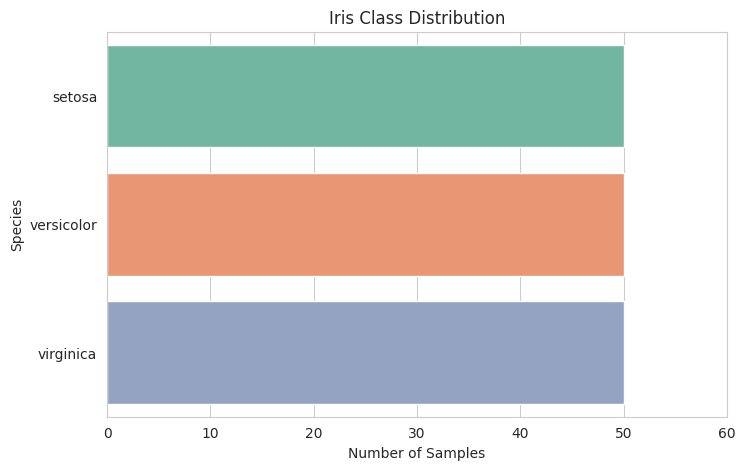

In [ ]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=class_counts.values,
    y=class_counts.index,
    hue=class_counts.index,
    palette='Set2',
)

plt.title('Iris Class Distribution')
plt.xlabel('Number of Samples')
plt.ylabel('Species')
plt.xlim(0, 60)
plt.show()

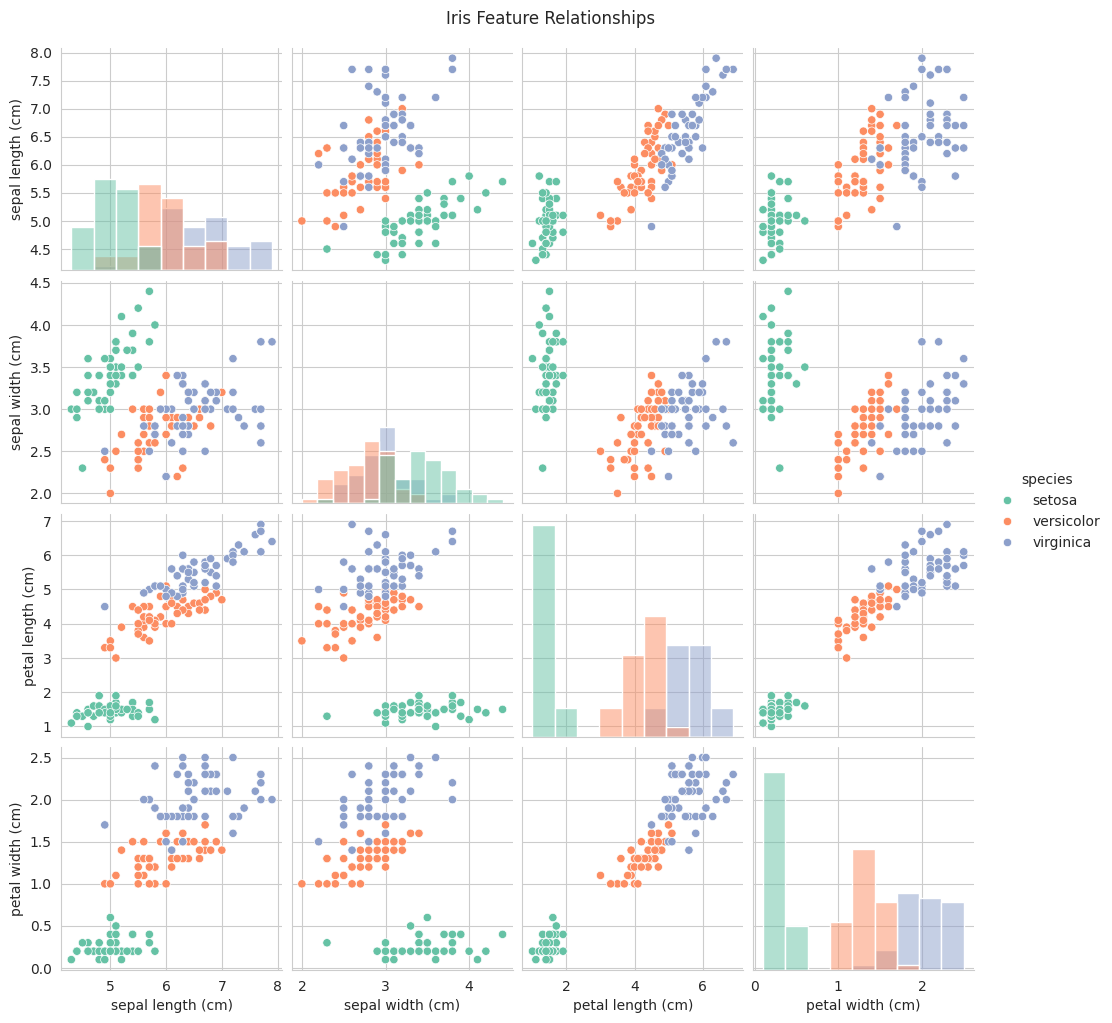

In [ ]:
sns.pairplot(
    df,
    vars=iris.feature_names,
    hue='species',
    palette='Set2',
    diag_kind='hist'
)

plt.suptitle('Iris Feature Relationships', y=1.02)
plt.show()

In [ ]:
# Features
X = df.drop(columns=['target', 'species'])

# Target
y = df['target']

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (150, 4)
Target Shape: (150,)


In [ ]:
# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,y,test_size=0.20,
    random_state=42, stratify=y
)

In [ ]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (120, 4)
X_test: (30, 4)
y_train: (120,)
y_test: (30,)


In [ ]:
# Create StandardScaler
scaler = StandardScaler()

In [ ]:
# Fit and transform training data
X_train_scaled = scaler.fit_transform(X_train)

In [ ]:
# Transform testing data
X_test_scaled = scaler.transform(X_test)

In [ ]:
print("Training shape:", X_train_scaled.shape)
print("Testing shape:", X_test_scaled.shape)

Training shape: (120, 4)
Testing shape: (30, 4)


In [ ]:
# Create Logistic Regression model
lr_model = LogisticRegression(
  max_iter=1000,random_state=42
)

# Train the model
lr_model.fit(X_train_scaled, y_train)

LogisticRegression(max_iter=1000, random_state=42)

In [ ]:
# Predict test data
y_pred_lr = lr_model.predict(X_test_scaled)

In [ ]:
print("Predictions:")
print(y_pred_lr)
print("Actual Values:")
print(y_test.values)

Predictions:
[0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 1 2 2 1 0 2 0]
Actual Values:
[0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 2 2 1 1 0 2 0]


In [ ]:
# Calculate evaluation metrics

accuracy = accuracy_score(y_test, y_pred_lr)

precision = precision_score(y_test, y_pred_lr,average='macro')

recall = recall_score(y_test, y_pred_lr,average='macro')

f1 = f1_score(y_test, y_pred_lr,average='macro')

print("Logistic Regression Evaluation")
print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1-Score:", f1)

Logistic Regression Evaluation
Accuracy: 0.9333333333333333
Precision: 0.9333333333333332
Recall: 0.9333333333333332
F1-Score: 0.9333333333333332


In [ ]:
print("Logistic Regression Classification Report")

print(classification_report(y_test,y_pred_lr,
      target_names=iris.target_names)
          )

Logistic Regression Classification Report
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



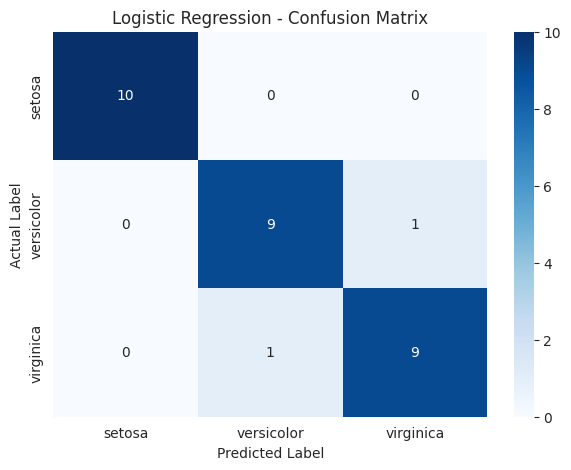

In [ ]:
cm_lr = confusion_matrix(y_test, y_pred_lr)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_lr,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=iris.target_names,
    yticklabels=iris.target_names
)

plt.title('Logistic Regression - Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')

plt.show()

In [ ]:
dt_model = DecisionTreeClassifier(
    random_state=42
)

dt_model.fit(X_train_scaled, y_train)

DecisionTreeClassifier(random_state=42)

In [ ]:
y_pred_dt = dt_model.predict(X_test_scaled)

print("Decision Tree Predictions:")
print(y_pred_dt)
print("Actual Values:")
print(y_test.values)

Decision Tree Predictions:
[0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 1 2 2 1 0 2 0]
Actual Values:
[0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 2 2 1 1 0 2 0]


In [ ]:
accuracy_dt = accuracy_score(y_test, y_pred_dt)

precision_dt = precision_score(
    y_test, y_pred_dt, average='macro'
)

recall_dt = recall_score(
    y_test, y_pred_dt, average='macro'
)

f1_dt = f1_score(
    y_test, y_pred_dt, average='macro'
)

print("Decision Tree Evaluation")
print("Accuracy:", accuracy_dt)
print("Precision:", precision_dt)
print("Recall:", recall_dt)
print("F1-Score:", f1_dt)

Decision Tree Evaluation
Accuracy: 0.9333333333333333
Precision: 0.9333333333333332
Recall: 0.9333333333333332
F1-Score: 0.9333333333333332


In [ ]:
print("Decision Tree Classification Report")

print(
    classification_report(
        y_test,
        y_pred_dt,
        target_names=iris.target_names
    )
)

Decision Tree Classification Report
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



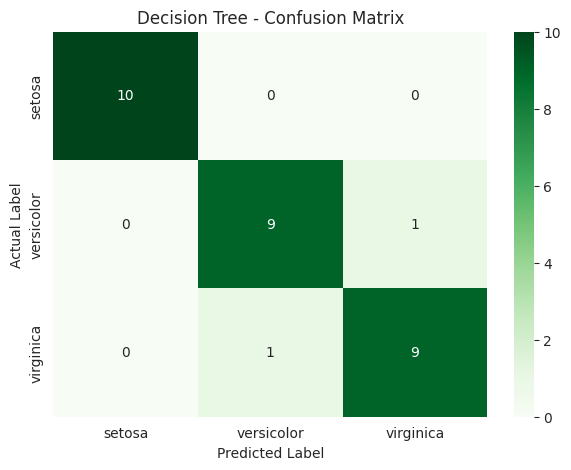

In [ ]:
cm_dt = confusion_matrix(y_test, y_pred_dt)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_dt,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=iris.target_names,
    yticklabels=iris.target_names
)

plt.title('Decision Tree - Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')

plt.show()

In [ ]:
comparison = pd.DataFrame({
    'Model': ['Logistic Regression', 'Decision Tree'],
    'Accuracy': [accuracy, accuracy_dt],
    'Precision': [precision, precision_dt],
    'Recall': [recall, recall_dt],
    'F1-Score': [f1, f1_dt]
})

comparison

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.933333,0.933333,0.933333,0.933333
1,Decision Tree,0.933333,0.933333,0.933333,0.933333


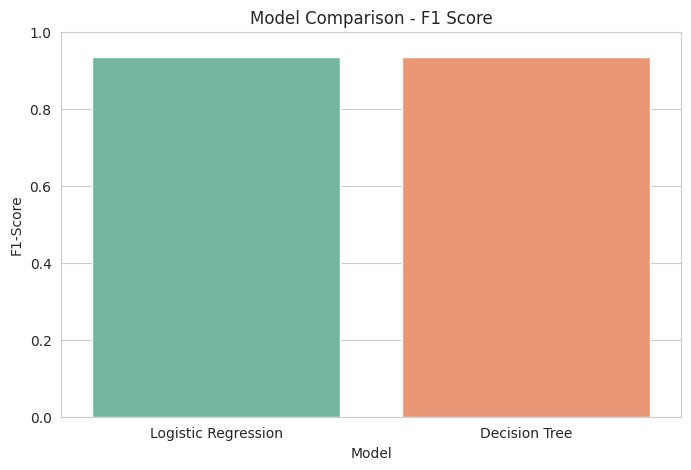

In [ ]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=comparison,
    x='Model',
    y='F1-Score',
    hue='Model',
    palette='Set2',
    legend=False
)

plt.title('Model Comparison - F1 Score')
plt.ylabel('F1-Score')
plt.xlabel('Model')
plt.ylim(0, 1)

plt.show()

In [ ]:
# Select two features for visualization
X_2d = df[
    ['petal length (cm)', 'petal width (cm)']
]

# Split the data
X_train_2d, X_test_2d, y_train_2d, y_test_2d = train_test_split(
    X_2d,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Scale the selected features
scaler_2d = StandardScaler()

X_train_2d_scaled = scaler_2d.fit_transform(X_train_2d)
X_test_2d_scaled = scaler_2d.transform(X_test_2d)

print("2D Data prepared successfully!")
print("Training shape:", X_train_2d_scaled.shape)
print("Testing shape:", X_test_2d_scaled.shape)

2D Data prepared successfully!
Training shape: (120, 2)
Testing shape: (30, 2)


In [ ]:
# Train a Logistic Regression model using two features
lr_2d = LogisticRegression(
    max_iter=1000,
    random_state=42
)

lr_2d.fit(X_train_2d_scaled, y_train_2d)

print("2D Logistic Regression trained successfully!")

2D Logistic Regression trained successfully!


In [ ]:
# Define the plot boundaries
x_min, x_max = X_train_2d_scaled[:, 0].min() - 1, X_train_2d_scaled[:, 0].max() + 1
y_min, y_max = X_train_2d_scaled[:, 1].min() - 1, X_train_2d_scaled[:, 1].max() + 1

# Create a mesh grid
xx, yy = np.meshgrid(
    np.arange(x_min, x_max, 0.02),
    np.arange(y_min, y_max, 0.02)
)

# Predict the class for each point
Z = lr_2d.predict(
    np.c_[xx.ravel(), yy.ravel()]
)

# Reshape predictions
Z = Z.reshape(xx.shape)

print("Decision boundary regions prepared!")

Decision boundary regions prepared!


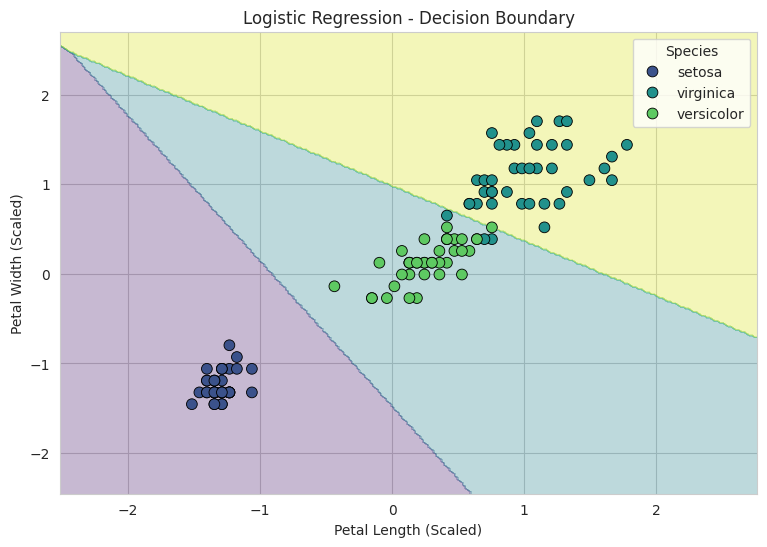

In [ ]:
plt.figure(figsize=(9, 6))

# Plot decision regions
plt.contourf(
    xx,
    yy,
    Z,
    alpha=0.3,
    cmap='viridis'
)

# Plot training samples
sns.scatterplot(
    x=X_train_2d_scaled[:, 0],
    y=X_train_2d_scaled[:, 1],
    hue=y_train_2d.map({
        0: 'setosa',
        1: 'versicolor',
        2: 'virginica'
    }),
    palette='viridis',
    s=60,
    edgecolor='black'
)

plt.title('Logistic Regression - Decision Boundary')
plt.xlabel('Petal Length (Scaled)')
plt.ylabel('Petal Width (Scaled)')
plt.legend(title='Species')
plt.show()

In [ ]:
dt_2d = DecisionTreeClassifier(
    random_state=42
)

dt_2d.fit(X_train_2d_scaled, y_train_2d)

print("2D Decision Tree trained successfully!")

2D Decision Tree trained successfully!


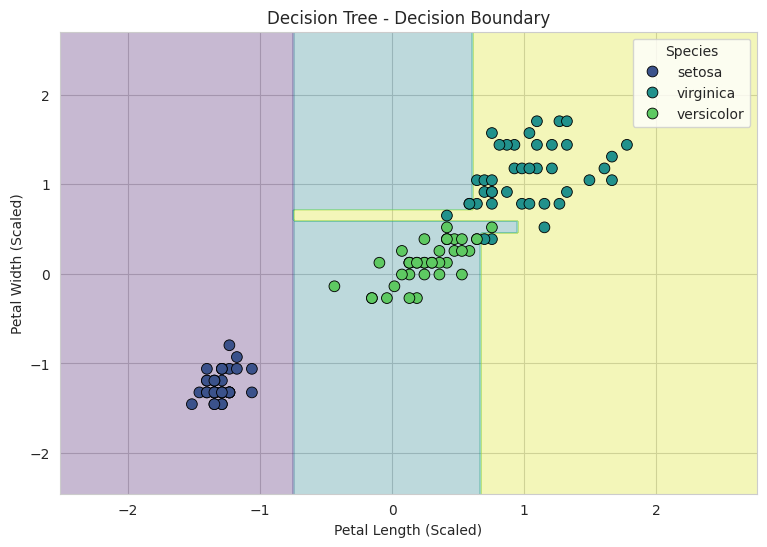

In [ ]:
# Predict classes for all grid points
Z_dt = dt_2d.predict(
    np.c_[xx.ravel(), yy.ravel()]
)

# Reshape predictions
Z_dt = Z_dt.reshape(xx.shape)

plt.figure(figsize=(9, 6))

# Plot decision regions
plt.contourf(
    xx,
    yy,
    Z_dt,
    alpha=0.3,
    cmap='viridis'
)

# Plot training samples
sns.scatterplot(
    x=X_train_2d_scaled[:, 0],
    y=X_train_2d_scaled[:, 1],
    hue=y_train_2d.map({
        0: 'setosa',
        1: 'versicolor',
        2: 'virginica'
    }),
    palette='viridis',
    s=60,
    edgecolor='black'
)

plt.title('Decision Tree - Decision Boundary')
plt.xlabel('Petal Length (Scaled)')
plt.ylabel('Petal Width (Scaled)')
plt.legend(title='Species')
plt.show()